<a href="https://colab.research.google.com/github/siojzz/Practical-Statistics-for-Data-Scientists/blob/main/PracticalStatisticsChapter7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Chapter 7 - Unsupervised Learning

This notebook contains my code reproduction and notes for Chapter 7 of *Practical Statistics for Data Scientists*.

This chapter focuses on unsupervised learning methods that explore patterns in data without using a known target variable.

The main topics are Principal Components Analysis (PCA), K-Means Clustering, Hierarchical Clustering, Model-Based Clustering, and data scaling.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from collections import Counter

from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.mixture import GaussianMixture

from scipy.cluster.hierarchy import linkage, dendrogram

In [2]:
base = "https://raw.githubusercontent.com/gedeck/practical-statistics-for-data-scientists/master/data"

!wget -O sp500_data.csv.gz "{base}/sp500_data.csv.gz"
!wget -O loan_data.csv.gz "{base}/loan_data.csv.gz"

--2026-10-24 11:17:22--  https://raw.githubusercontent.com/gedeck/practical-statistics-for-data-scientists/master/data/sp500_data.csv.gz
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.110.133, 185.199.108.133, 185.199.111.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.110.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 21152050 (20M) [application/octet-stream]
Saving to: ‘sp500_data.csv.gz’

sp500_data.csv.gz   100%[===================>]  20.17M  50.7MB/s    in 0.4s    

2026-10-24 11:17:24 (50.7 MB/s) - ‘sp500_data.csv.gz’ saved [21152050/21152050]

--2026-10-24 11:17:24--  https://raw.githubusercontent.com/gedeck/practical-statistics-for-data-scientists/master/data/loan_data.csv.gz
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443.

In [3]:
sp500_px = pd.read_csv(
    "sp500_data.csv.gz",
    index_col=0
)

sp500_px.index = pd.to_datetime(sp500_px.index)

loan_data = pd.read_csv(
    "loan_data.csv.gz"
)

sp500_px.head()

,ADS,CA,MSFT,RHT,CTSH,CSC,EMC,IBM,XRX,ALTR,...,WAT,ALXN,AMGN,BXLT,BIIB,CELG,GILD,REGN,VRTX,HSIC
1993-01-29,0.0,0.060124,-0.022100,0.0,0.0,0.018897,0.007368,0.092165,0.259140,-0.007105,...,0.0,0.0,0.34716,0.0,0.04167,0.00000,0.015564,1.75,0.1250,0.0
1993-02-01,0.0,-0.180389,0.027621,0.0,0.0,0.018889,0.018425,0.115207,-0.100775,0.063893,...,0.0,0.0,-0.23144,0.0,0.00000,-0.01041,0.007782,1.25,0.1250,0.0
1993-02-02,0.0,-0.120257,0.035900,0.0,0.0,-0.075573,0.029482,-0.023041,0.028796,-0.014192,...,0.0,0.0,-0.11572,0.0,0.00000,0.00000,-0.007792,-0.25,0.0000,0.0
1993-02-03,0.0,0.060124,-0.024857,0.0,0.0,-0.151128,0.003689,-0.253454,-0.043190,-0.007105,...,0.0,0.0,-0.08679,0.0,0.04167,-0.04167,-0.038919,-0.50,0.0625,0.0
1993-02-04,0.0,-0.360770,-0.060757,0.0,0.0,0.113350,-0.022114,0.069862,0.000000,-0.007096,...,0.0,0.0,0.14465,0.0,-0.04166,-0.03126,-0.046711,0.00,0.0625,0.0


## 1. Principal Components Analysis

Principal Components Analysis (PCA) is a method for reducing the number of variables in a dataset.

PCA creates new variables called principal components. These components are combinations of the original numerical variables.

The first principal component explains the largest amount of variation in the data. The next components explain the remaining variation while being uncorrelated with the previous components.

In [4]:
oil_px = sp500_px[
    ["CVX", "XOM"]
]

pcs = PCA(
    n_components=2
)

pcs.fit(oil_px)

loadings = pd.DataFrame(
    pcs.components_,
    columns=oil_px.columns
)

loadings

,CVX,XOM
0,0.747101,0.664711
1,-0.664711,0.747101


**Interpretation:**

The first principal component represents the common movement between CVX and XOM.

The second principal component represents differences in the movements of the two stocks.

PCA summarizes the original variables using new components that capture most of the variation.

In [5]:
explained_variance = pd.DataFrame({
    "Component": ["PC1", "PC2"],
    "Explained Variance": pcs.explained_variance_ratio_
})

explained_variance

,Component,Explained Variance
0,PC1,0.895858
1,PC2,0.104142


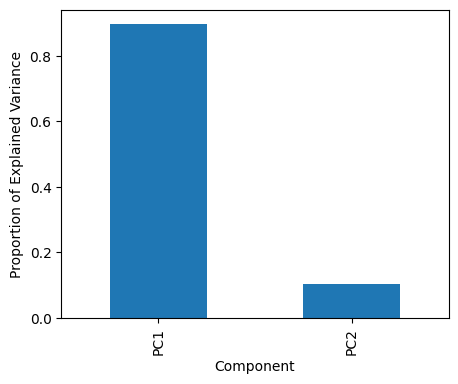

In [6]:
explained_variance.plot.bar(
    x="Component",
    y="Explained Variance",
    legend=False,
    figsize=(5, 4)
)

plt.ylabel("Proportion of Explained Variance")
plt.show()

### 1.1 Interpreting Principal Components

A scree plot is used to show the amount of variance explained by each principal component.

Components with larger explained variance contain more information about the original dataset.

In [7]:
syms = sorted([
    "AAPL", "MSFT", "CSCO", "INTC",
    "CVX", "XOM", "SLB", "COP",
    "JPM", "WFC", "USB", "AXP",
    "WMT", "TGT", "HD", "COST"
])

top_sp = sp500_px.loc[
    sp500_px.index >= "2011-01-01",
    syms
]

sp_pca = PCA()

sp_pca.fit(top_sp)

PCA()

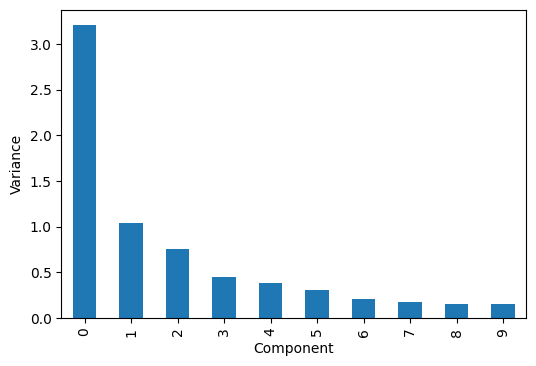

In [8]:
explained_variance = pd.DataFrame(
    sp_pca.explained_variance_
)

ax = explained_variance.head(10).plot.bar(
    legend=False,
    figsize=(6, 4)
)

ax.set_xlabel("Component")
ax.set_ylabel("Variance")

plt.show()

In [9]:
loadings = pd.DataFrame(
    sp_pca.components_[0:5, :],
    columns=top_sp.columns
)

loadings.transpose()

,0,1,2,3,4
AAPL,0.300825,0.505116,0.786730,-0.120586,-0.111576
AXP,0.246332,0.139426,-0.135458,0.061814,0.596666
COP,0.261529,-0.174212,0.002367,-0.206026,0.005813
COST,0.273634,0.416307,-0.465862,0.092596,-0.555529
CSCO,0.064059,0.031939,0.007524,0.003904,0.039860
CVX,0.444490,-0.289373,-0.082374,-0.577665,-0.109016
HD,0.207983,0.278002,-0.166320,0.162814,0.185488
INTC,0.076956,0.033898,0.003518,-0.001605,0.072047
JPM,0.196397,0.040723,-0.062261,0.057687,0.385160
MSFT,0.105012,0.053954,-0.016248,-0.012558,0.077135


**Interpretation:**

The first few principal components explain more variation than the later components.

The loading values show how strongly each original stock contributes to each principal component.

## 2. Correspondence Analysis

Correspondence Analysis is a technique that is similar in purpose to PCA but is designed for categorical data.

It can be used to explore relationships between categories in a contingency table.

Unlike PCA, which works mainly with numerical variables, Correspondence Analysis focuses on categorical variables.

In modern large-scale data science applications, this method is less commonly used than PCA and clustering.

## 3. K-Means Clustering

K-Means is an unsupervised learning method that divides observations into groups called clusters.

Observations inside the same cluster should be similar to each other, while observations from different clusters should be different.

The number of clusters is represented by K.

In [10]:
df = sp500_px.loc[
    sp500_px.index >= "2011-01-01",
    ["XOM", "CVX"]
].copy()

kmeans = KMeans(
    n_clusters=4,
    random_state=1,
    n_init=10
)

kmeans.fit(df)

KMeans(n_clusters=4, n_init=10, random_state=1)

In [11]:
df["cluster"] = kmeans.labels_

df.head()

,XOM,CVX,cluster
2011-01-03,0.736805,0.240681,3
2011-01-04,0.168668,-0.584516,0
2011-01-05,0.026631,0.446985,3
2011-01-06,0.248558,-0.919751,0
2011-01-07,0.337329,0.180511,3


In [12]:
centers = pd.DataFrame(
    kmeans.cluster_centers_,
    columns=["XOM", "CVX"]
)

centers

,XOM,CVX
0,-0.328486,-0.566914
1,-1.143980,-1.750297
2,0.958269,1.374154
3,0.242011,0.335179


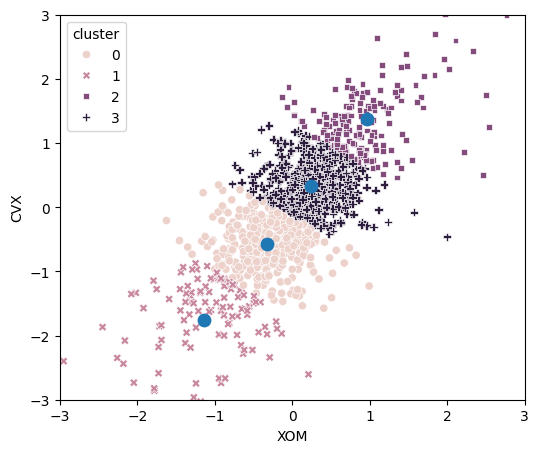

In [13]:
fig, ax = plt.subplots(figsize=(6, 5))

sns.scatterplot(
    data=df,
    x="XOM",
    y="CVX",
    hue="cluster",
    style="cluster",
    ax=ax
)

centers.plot.scatter(
    x="XOM",
    y="CVX",
    ax=ax,
    s=80
)

ax.set_xlim(-3, 3)
ax.set_ylim(-3, 3)

plt.show()

**Interpretation:**

K-Means separates the daily stock returns into four groups.

Each cluster represents observations with similar movements in XOM and CVX.

The cluster centers represent the average position of observations inside each cluster.

### 3.2 K-Means Algorithm

The K-Means algorithm begins with K initial cluster centers.

It then repeats two main steps:

1. Assign each observation to the nearest cluster center.
2. Recalculate each cluster center using the observations assigned to it.

The process continues until the cluster assignments become stable.

In [14]:
syms = sorted([
    "AAPL", "MSFT", "CSCO", "INTC",
    "CVX", "XOM", "SLB", "COP",
    "JPM", "WFC", "USB", "AXP",
    "WMT", "TGT", "HD", "COST"
])

top_sp = sp500_px.loc[
    sp500_px.index >= "2011-01-01",
    syms
]

kmeans_stock = KMeans(
    n_clusters=5,
    random_state=1,
    n_init=10
)

kmeans_stock.fit(top_sp)

KMeans(n_clusters=5, n_init=10, random_state=1)

In [15]:
Counter(
    kmeans_stock.labels_
)

Counter({np.int32(1): 301,
         np.int32(0): 272,
         np.int32(4): 287,
         np.int32(2): 158,
         np.int32(3): 113})

In [16]:
stock_centers = pd.DataFrame(
    kmeans_stock.cluster_centers_,
    columns=syms
)

stock_centers

,AAPL,AXP,COP,COST,CSCO,CVX,HD,INTC,JPM,MSFT,SLB,TGT,USB,WFC,WMT,XOM
0,-0.322273,-0.194407,-0.396402,-0.061042,-0.056981,-0.659930,-0.087945,-0.056061,-0.123485,-0.056467,-0.835978,-0.072949,-0.060351,-0.108498,-0.027345,-0.390886
1,0.711762,0.300819,0.071396,0.416804,0.081684,0.101531,0.374788,0.099252,0.165170,0.123406,0.016155,0.306727,0.113064,0.136861,0.238733,0.138073
2,0.516247,0.561074,0.672157,0.688480,0.158834,1.231947,0.540877,0.214350,0.477299,0.280358,1.470565,0.303695,0.298622,0.360395,0.357054,0.920538
3,-1.220575,-0.976577,-0.860544,-1.080674,-0.220340,-1.384551,-0.748617,-0.292684,-0.782745,-0.390649,-1.420097,-0.604351,-0.425814,-0.537322,-0.394938,-0.986052
4,-0.420501,0.013293,0.211051,-0.250562,0.009929,0.368967,-0.180261,0.023347,0.035383,-0.012545,0.409205,-0.149496,-0.008143,0.011895,-0.131172,0.225727


## 4. Selecting the Number of Clusters

K-Means requires the number of clusters to be selected before training.

One common approach is the elbow method.

The elbow method compares the within-cluster variation for different values of K.

A useful K can sometimes be found where adding more clusters produces only a small improvement.

In [17]:
inertia = []

for n_clusters in range(2, 14):

    model = KMeans(
        n_clusters=n_clusters,
        random_state=1,
        n_init=10
    )

    model.fit(top_sp)

    inertia.append(
        model.inertia_ / n_clusters
    )

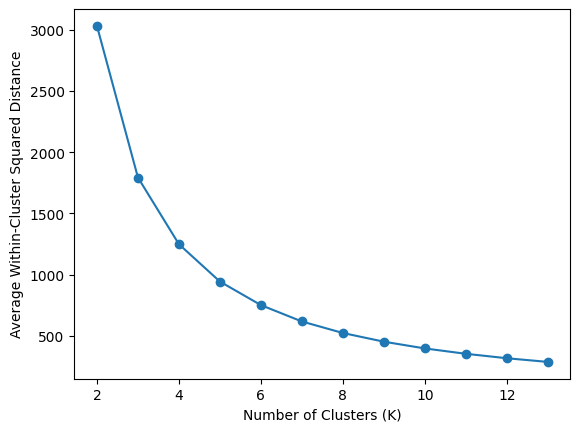

In [18]:
inertias = pd.DataFrame({
    "n_clusters": range(2, 14),
    "inertia": inertia
})

ax = inertias.plot(
    x="n_clusters",
    y="inertia",
    marker="o",
    legend=False
)

ax.set_xlabel("Number of Clusters (K)")
ax.set_ylabel(
    "Average Within-Cluster Squared Distance"
)

plt.show()

**Interpretation:**

The elbow plot helps compare different numbers of clusters.

A possible value of K can be selected where the reduction in within-cluster variation begins to become smaller.

## 5. Hierarchical Clustering

Hierarchical clustering creates a hierarchy of clusters.

It begins with each observation as its own cluster and gradually combines the most similar clusters.

Unlike K-Means, hierarchical clustering does not require the final number of clusters to be specified before the clustering process.

In [19]:
syms1 = [
    "AAPL", "AMZN", "AXP", "COP",
    "COST", "CSCO", "CVX", "GOOGL",
    "HD", "INTC", "JPM", "MSFT",
    "SLB", "TGT", "USB", "WFC",
    "WMT", "XOM"
]

hier_data = sp500_px.loc[
    sp500_px.index >= "2011-01-01",
    syms1
].transpose()

Z = linkage(
    hier_data,
    method="complete"
)

### 5.1 Dendrogram

A dendrogram is a tree-like visualization of hierarchical clustering.

Observations that join together at shorter distances are more similar.

The height of each connection represents the distance between clusters.

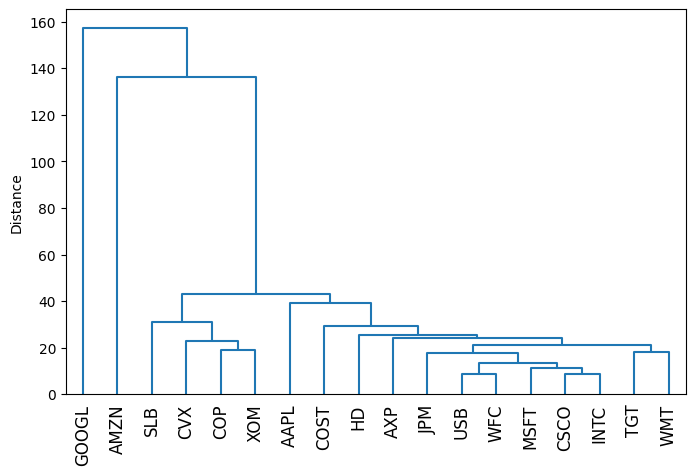

In [20]:
fig, ax = plt.subplots(
    figsize=(8, 5)
)

dendrogram(
    Z,
    labels=hier_data.index,
    ax=ax,
    color_threshold=0
)

plt.xticks(rotation=90)

ax.set_ylabel("Distance")

plt.show()

**Interpretation:**

Stocks that are connected at smaller distances have more similar return patterns.

The dendrogram allows us to visually explore different possible numbers of clusters without specifying the number of clusters in advance.

### 5.2 Agglomerative Algorithm

Hierarchical clustering commonly uses an agglomerative approach.

The algorithm starts with every observation as a separate cluster.

The two most similar clusters are repeatedly merged until all observations belong to one large cluster.

### Measures of Dissimilarity

Different linkage methods can be used to measure the distance between clusters.

Common methods include:

- Complete linkage
- Single linkage
- Average linkage
- Ward's method

Different linkage methods can produce different clustering results.

## 6. Model-Based Clustering

Model-Based Clustering assumes that the data comes from several probability distributions.

Each cluster is represented by a statistical distribution.

A common implementation uses a mixture of multivariate normal distributions.

### Multivariate Normal Distribution

A multivariate normal distribution extends the normal distribution to multiple variables.

Each distribution has a mean vector and a covariance matrix that describe its position and shape.

### Mixtures of Normals

A mixture model assumes that observations are generated from several different probability distributions.

Each distribution represents one possible cluster in the data.

In [21]:
model_df = sp500_px.loc[
    sp500_px.index >= "2011-01-01",
    ["XOM", "CVX"]
]

mclust = GaussianMixture(
    n_components=2,
    random_state=1
)

mclust.fit(model_df)

GaussianMixture(n_components=2, random_state=1)

In [22]:
print(
    "BIC:",
    mclust.bic(model_df)
)

BIC: 4589.9288573186395


In [23]:
model_clusters = mclust.predict(
    model_df
)

model_clusters[:10]

array([1, 1, 1, 0, 1, 1, 1, 1, 1, 1])

In [24]:
print("Means:")
print(
    mclust.means_
)

print("\nCovariances:")
print(
    mclust.covariances_
)

Means:
[[-0.05031426 -0.21161823]
 [ 0.07246995  0.10494619]]

Covariances:
[[[0.97123064 0.97764343]
  [0.97764343 1.67233845]]

 [[0.26822676 0.27562091]
  [0.27562091 0.51679853]]]


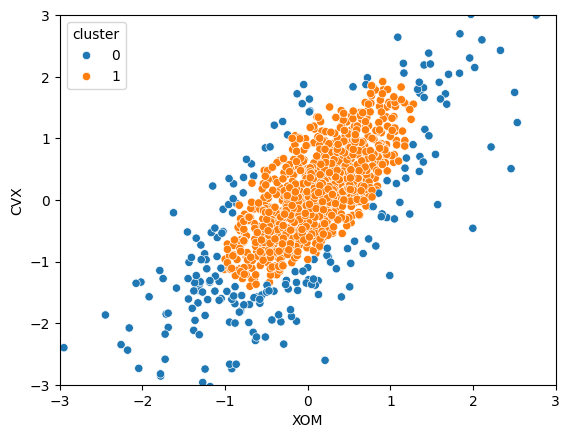

In [25]:
plot_df = model_df.copy()

plot_df["cluster"] = model_clusters

sns.scatterplot(
    data=plot_df,
    x="XOM",
    y="CVX",
    hue="cluster"
)

plt.xlim(-3, 3)
plt.ylim(-3, 3)

plt.show()

**Interpretation:**

The Gaussian Mixture Model divides the observations according to estimated probability distributions.

Unlike K-Means, the clusters are based on statistical distributions rather than only distance from cluster centers.

### 6.1 Selecting the Number of Clusters

Model-Based Clustering can use the Bayesian Information Criterion (BIC) to compare different models.

A lower BIC value indicates a better balance between model fit and model complexity.

In [26]:
results = []

covariance_types = [
    "full",
    "tied",
    "diag",
    "spherical"
]

for n_components in range(1, 9):

    for covariance_type in covariance_types:

        model = GaussianMixture(
            n_components=n_components,
            covariance_type=covariance_type,
            random_state=1
        )

        model.fit(model_df)

        results.append({
            "bic": model.bic(model_df),
            "n_components": n_components,
            "covariance_type": covariance_type
        })

In [27]:
bic_results = pd.DataFrame(
    results
)

bic_results.head()

,bic,n_components,covariance_type
0,4662.479542,1,full
1,4662.479542,1,tied
2,5623.004733,1,diag
3,5716.701969,1,spherical
4,4589.928857,2,full


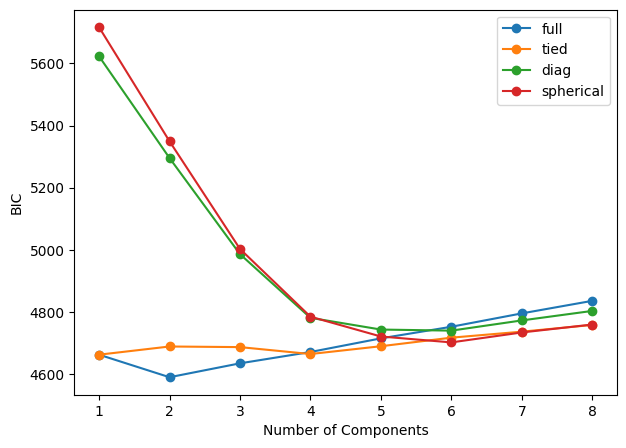

In [28]:
fig, ax = plt.subplots(
    figsize=(7, 5)
)

for covariance_type in covariance_types:

    subset = bic_results[
        bic_results["covariance_type"]
        == covariance_type
    ]

    ax.plot(
        subset["n_components"],
        subset["bic"],
        marker="o",
        label=covariance_type
    )

ax.set_xlabel(
    "Number of Components"
)

ax.set_ylabel(
    "BIC"
)

ax.legend()

plt.show()

## 7. Scaling and Categorical Variables

Unsupervised learning methods are sensitive to the scale of the predictor variables.

Variables with large numerical values can dominate PCA and clustering methods.

Standardization is commonly used to place variables on comparable scales.

In [29]:
defaults = loan_data.loc[
    loan_data["outcome"]
    == "default"
]

columns = [
    "loan_amnt",
    "annual_inc",
    "revol_bal",
    "open_acc",
    "dti",
    "revol_util"
]

loan_df = defaults[
    columns
]

In [30]:
kmeans_unscaled = KMeans(
    n_clusters=4,
    random_state=1,
    n_init=10
)

kmeans_unscaled.fit(
    loan_df
)

counts = Counter(
    kmeans_unscaled.labels_
)

centers = pd.DataFrame(
    kmeans_unscaled.cluster_centers_,
    columns=columns
)

centers["size"] = [
    counts[i]
    for i in range(4)
]

centers

,loan_amnt,annual_inc,revol_bal,open_acc,dti,revol_util,size
0,10622.742745,42577.468936,10301.719025,9.594482,17.708084,58.125058,13949
1,18312.358465,83793.803650,19740.572666,11.677767,16.771941,62.307165,7509
2,21924.589455,166721.916162,39129.990493,12.566119,13.374546,63.505161,1161
3,22570.192308,489783.403846,85161.346154,13.326923,6.907500,59.651923,52


In [31]:
scaler = StandardScaler()

loan_scaled = scaler.fit_transform(
    loan_df
)

kmeans_scaled = KMeans(
    n_clusters=4,
    random_state=1,
    n_init=10
)

kmeans_scaled.fit(
    loan_scaled
)

counts = Counter(
    kmeans_scaled.labels_
)

scaled_centers = pd.DataFrame(
    scaler.inverse_transform(
        kmeans_scaled.cluster_centers_
    ),
    columns=columns
)

scaled_centers["size"] = [
    counts[i]
    for i in range(4)
]

scaled_centers

,loan_amnt,annual_inc,revol_bal,open_acc,dti,revol_util,size
0,25911.917975,116436.183541,32850.199242,12.417163,16.199721,66.075439,3704
1,10353.683267,53506.668364,6049.698547,8.699868,11.347761,30.578083,5306
2,13394.423718,55638.622956,16409.356247,14.235910,24.232926,59.758967,6292
3,10475.352447,51152.617595,11505.237088,7.473092,15.754014,77.654009,7369


**Interpretation:**

Without scaling, variables with large numerical values can dominate the clustering result.

After standardization, each variable has a more balanced influence on the clustering process.

## 8. Categorical Data and Gower's Distance

Categorical variables create additional challenges for clustering.

One-hot encoding can convert categorical variables into binary variables, but these binary variables may behave differently from continuous numerical variables.

Gower's distance is one method designed for datasets containing both numerical and categorical variables.

It scales the contribution of variables so that different data types can be compared more fairly.

### 8.1 Problems with Clustering Mixed Data

K-Means and PCA are mainly designed for continuous numerical variables.

Using many binary or categorical variables can strongly influence the resulting clusters.

For datasets containing mixed data types, hierarchical clustering with an appropriate distance measure such as Gower's distance can sometimes be more appropriate.

## 9. Chapter Summary

In this chapter, I learned the main concepts of unsupervised learning.

The main topics covered were:

- Principal Components Analysis (PCA)
- Principal component loadings
- Explained variance and scree plots
- Correspondence Analysis
- K-Means Clustering
- Cluster centers
- Selecting K using the elbow method
- Hierarchical Clustering
- Dendrograms
- Linkage methods
- Model-Based Clustering
- Gaussian Mixture Models
- Bayesian Information Criterion (BIC)
- Scaling and standardization
- Categorical variables
- Gower's distance

PCA is useful for reducing the number of numerical variables while keeping much of the original variation.

Clustering methods such as K-Means, hierarchical clustering, and Gaussian mixture models are used to discover groups in data without using a known outcome variable.

Scaling is especially important in unsupervised learning because variables with large numerical values can dominate the analysis.